# Evaluation - Comparing CGAN and Conditional Diffusion 

In [1]:
# Reproducibility
import random
import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
print(f"Random seed set to {SEED}")


Random seed set to 42


## Plan

1. Understand how to measure the quality and diversity of generated data using **FID**.  
2. Compare **cGAN vs Diffusion** outputs visually and statistically.  
3. Train a downstream **handwriting classifier** using synthetic data.  
4. Assess which generative approach produces more *useful* data for CAPTCHA robustness.



### Objectives to check
+ Do the samples look human like 
+ we would measure the quantititative quality using Frechet Inception Distance 
+ Also work on using sythetic data from each model to train a useful classifier

In [2]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import inception_v3
from torchvision.utils import make_grid
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import os, sys
from scipy import linalg


from utils.visualize import show_batch
from utils.checkpoint import load_checkpoint
from torchmetrics.image.fid import FrechetInceptionDistance

We’ll now load both trained models - the **cGAN** and **Diffusion** generators -  
and use them to generate a fixed number of samples for evaluation.

In [3]:
from model.cgan import Generator
from model.diffusion import ConditionalUNet
from training.train_diffusion import sample_images

device = (
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print(f" Using device: {device}")



 Using device: cuda


In [4]:
# Helper functions

from training.train_diffusion import linear_beta_schedule
from utils.metrics import fid_score


def get_real_examples_per_class(n_classes=10, n_per_class=1):
    """
    Deterministically extracts `n_per_class` MNIST test images per class (0-9).
    """
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])
    mnist = datasets.MNIST(root="../data", train=False, download=True, transform=transform)

    imgs, labels = [], []
    targets = mnist.targets
    for cls in range(n_classes):
        indices = (targets == cls).nonzero(as_tuple=True)[0][:n_per_class]
        for i in indices.tolist():
            img, label = mnist[i]
            imgs.append(img)
            labels.append(label)
    return torch.stack(imgs), torch.tensor(labels)


def get_representative_images(imgs, labels, n_classes=10):
    """
    Returns one representative image per class label (0-9).
    """
    reps = []
    for i in range(n_classes):
        idx = (labels == i).nonzero(as_tuple=True)[0]
        if len(idx) > 0:
            reps.append(imgs[idx[0]])
        else:
            reps.append(torch.zeros_like(imgs[0]))
    return torch.stack(reps)


@torch.no_grad()
def generate_conditioned_samples_cgan(generator, z_dim=100, device="cuda", n_classes=10, n_per_class=1):
    """
    Generate `n_per_class` cGAN samples per class and return images + labels.
    """
    generator.eval()
    imgs_list, labels_list = [], []
    for cls in range(n_classes):
        zs = torch.randn(n_per_class, z_dim, device=device)
        ys = torch.full((n_per_class,), cls, dtype=torch.long, device=device)
        imgs_list.append(generator(zs, ys).cpu())
        labels_list.append(ys.cpu())
    generator.train()
    return torch.cat(imgs_list), torch.cat(labels_list)


@torch.no_grad()
def generate_conditioned_samples_diffusion(
    model,
    device="cuda",
    n_classes=10,
    n_per_class=1,
    timesteps=200,
    img_size=(1, 28, 28),
):
    """
    Generate `n_per_class` diffusion samples per class one class batch at a time
    to respect the 4 GB VRAM guard-rail.
    """
    model.eval()
    imgs_list, labels_list = [], []
    for cls in range(n_classes):
        labels = torch.full((n_per_class,), cls, dtype=torch.long, device=device)
        imgs, labs = sample_images(
            model,
            device,
            num_samples=n_per_class,
            num_classes=n_classes,
            img_size=img_size,
            timesteps=timesteps,
            class_labels=labels,
        )
        imgs_list.append(imgs.cpu())
        labels_list.append(labs.cpu())
    return torch.cat(imgs_list), torch.cat(labels_list)


def plot_real_cgan_diffusion(real_imgs, cgan_imgs, diff_imgs, n_classes=10):
    """
    Visual comparison between Real, cGAN, and Diffusion images.
    """
    fig, axs = plt.subplots(3, n_classes, figsize=(12, 4))
    fig.suptitle("Comparison: Real vs cGAN vs Diffusion", fontsize=14, fontweight="bold")

    row_titles = ["Ground Truth", "CGAN", "Diffusion"]
    row_colors = ["green", "royalblue", "darkorange"]

    for row_idx, row_imgs in enumerate([real_imgs, cgan_imgs, diff_imgs]):
        for i in range(n_classes):
            axs[row_idx, i].imshow(row_imgs[i].squeeze(), cmap="gray")
            axs[row_idx, i].axis("off")
            axs[row_idx, i].set_title(f"Class {i}", fontsize=8, pad=2)

    for idx, (title, color) in enumerate(zip(row_titles, row_colors)):
        fig.text(
            0.02,
            0.84 - idx * 0.32,
            title,
            fontsize=11,
            color=color,
            fontweight="bold",
            va="center",
        )

    plt.subplots_adjust(left=0.12, right=0.98, top=0.9, bottom=0.05, hspace=0.3)
    plt.show()


In [5]:


def compute_fid(real_imgs, fake_imgs, device="cuda", batch_size=128):
    """
    Compute FID safely in GPU batches to prevent OOM.
    Works with TorchMetrics' FrechetInceptionDistance.
    """
    fid = FrechetInceptionDistance(normalize=True).to(device)
    fid.reset()

    def batched_update(imgs, real_flag):
        for i in tqdm(range(0, imgs.size(0), batch_size), desc=f"FID {'real' if real_flag else 'fake'}"):
            batch = imgs[i:i + batch_size].to(device, non_blocking=True)
            fid.update(batch, real=real_flag)
            torch.cuda.empty_cache()


    real_imgs_rgb = (real_imgs.repeat(1, 3, 1, 1) + 1) / 2
    fake_imgs_rgb = (fake_imgs.repeat(1, 3, 1, 1) + 1) / 2
    real_imgs_rgb = torch.clamp(real_imgs_rgb, 0, 1)
    fake_imgs_rgb = torch.clamp(fake_imgs_rgb, 0, 1)

    batched_update(real_imgs_rgb, real_flag=True)
    batched_update(fake_imgs_rgb, real_flag=False)

    score = fid.compute().item()
    return score

In [6]:
# Safety clean up
torch.cuda.empty_cache()

In [7]:
# Load trained checkpoints (adjust path if different)
os.makedirs("../checkpoints", exist_ok=True)

# Initialise the cGAN Generator and the conditional UNet, then restore weights
cgan_gen = Generator(z_dim=100, num_classes=10).to(device)
diff_model = ConditionalUNet(num_classes=10).to(device)

load_checkpoint(cgan_gen, path="../checkpoints/cgan_generator_epochfinal.pt", map_location=device)
load_checkpoint(diff_model, path="../checkpoints/diffusion_unet_epochfinal.pt", map_location=device)

cgan_gen.eval()
diff_model.eval()


Loaded model weights from ../checkpoints/cgan_generator_epochfinal.pt
Loaded model weights from ../checkpoints/diffusion_unet_epochfinal.pt


ConditionalUNet(
  (time_mlp): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
  )
  (down1): ResidualBlock(
    (conv1): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (norm1): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (norm2): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
    (time_emb): Linear(in_features=128, out_features=64, bias=True)
    (label_emb): Embedding(10, 64)
    (shortcut): Conv2d(1, 64, kernel_size=(1, 1), stride=(1, 1))
  )
  (down2): ResidualBlock(
    (conv1): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (norm1): GroupNorm(8, 128, eps=1e-05, affine=True, bias=True)
    (conv2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (norm2): GroupNorm(8, 128, eps=1e-05, affine=True, bias=True)
    (time

In [8]:
N_PER_CLASS = 100  # 100 synthetic samples per digit -> 1000 per model

real_imgs, real_labels = get_real_examples_per_class()

# Generate 100 samples per class for each model
cgan_imgs, cgan_labels = generate_conditioned_samples_cgan(
    cgan_gen, device=device, n_per_class=N_PER_CLASS
)
diff_imgs, diff_labels = generate_conditioned_samples_diffusion(
    diff_model, device=device, n_per_class=N_PER_CLASS, timesteps=200
)

print(f"cGAN samples:      {tuple(cgan_imgs.shape)} | labels: {cgan_labels.unique().tolist()}")
print(f"Diffusion samples: {tuple(diff_imgs.shape)} | labels: {diff_labels.unique().tolist()}")


cGAN samples:      (1000, 1, 28, 28) | labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Diffusion samples: (1000, 1, 28, 28) | labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


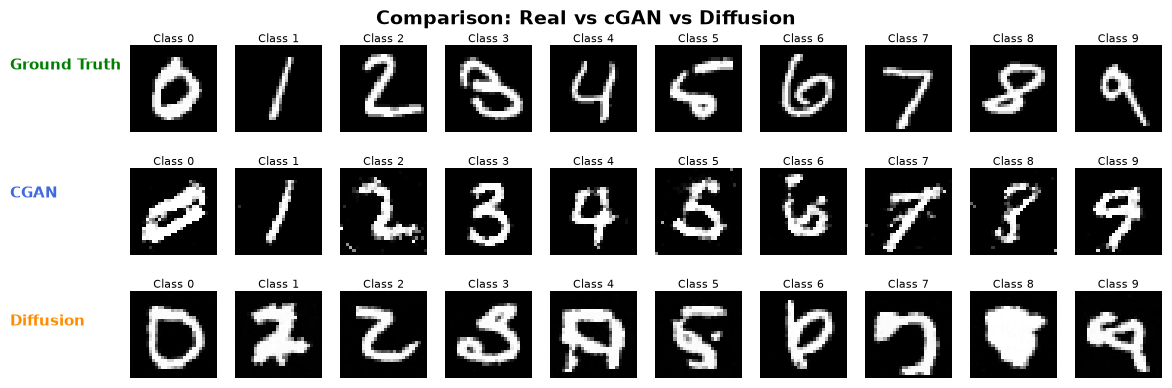

In [9]:
# Plot evaluation image: one representative sample per digit and model
real_reps = get_representative_images(real_imgs, real_labels)
cgan_reps = get_representative_images(cgan_imgs, cgan_labels)
diff_reps = get_representative_images(diff_imgs, diff_labels)

plot_real_cgan_diffusion(real_reps, cgan_reps, diff_reps, n_classes=10)


In [10]:

fid = FrechetInceptionDistance(normalize=True).to(device)
fid.reset()

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to C:\Users\eduardo.nicacio/.cache\torch\hub\checkpoints\weights-inception-2015-12-05-6726825d.pth


  0%|          | 0.00/91.2M [00:00<?, ?B/s]

  0%|          | 256k/91.2M [00:00<00:38, 2.49MB/s]

  2%|▏         | 2.12M/91.2M [00:00<00:07, 12.3MB/s]

  9%|▉         | 8.50M/91.2M [00:00<00:02, 36.8MB/s]

 17%|█▋        | 15.8M/91.2M [00:00<00:01, 51.2MB/s]

... (4 outputs left out)

 68%|██████▊   | 62.4M/91.2M [00:00<00:00, 83.8MB/s]

 82%|████████▏ | 74.5M/91.2M [00:01<00:00, 95.8MB/s]

 92%|█████████▏| 83.8M/91.2M [00:01<00:00, 92.5MB/s]

100%|██████████| 91.2M/91.2M [00:01<00:00, 77.2MB/s]

In [11]:
torch.cuda.empty_cache()

In [12]:
# Balanced real subset with the same number of images as each synthetic set
real_subset, real_subset_labels = get_real_examples_per_class(n_per_class=N_PER_CLASS)
print(f"FID sets -> real: {real_subset.size(0)} | cGAN: {cgan_imgs.size(0)} | diffusion: {diff_imgs.size(0)}")


FID sets -> real: 1000 | cGAN: 1000 | diffusion: 1000


In [13]:
# Compute cGAN FID & Diffusion FID (lower is better)
cgan_fid = fid_score(real_subset, cgan_imgs, device=device)
diff_fid = fid_score(real_subset, diff_imgs, device=device)

print(f" cGAN FID: {cgan_fid:.2f}")
print(f"Diffusion FID: {diff_fid:.2f}")


 cGAN FID: 69.92
Diffusion FID: 33.72


**FID analysis**

| Model | FID (lower is better) |
|---|---|
| cGAN | **69.92** |
| Conditional diffusion | **33.72** |

FID compares the distribution of 1000 synthetic digits with 1000 real MNIST
digits in Inception feature space. The diffusion model scores roughly half the
cGAN's FID, so its samples are both more realistic and more diverse: the cGAN
suffers from the usual adversarial instability and covers fewer handwriting
styles (its strokes look smoother and more repetitive in the grid above).


### Utility Evaluation (Classifier)

We’ll train a simple CNN classifier on synthetic data from each model,  
then test it on real MNIST data.

If synthetic data are realistic and diverse, the classifier should generalize well to real digits.

In [14]:
cgan_imgs, cgan_labels = generate_conditioned_samples_cgan(
    cgan_gen, device=device, n_per_class=100
)
diff_imgs, diff_labels = generate_conditioned_samples_diffusion(
    diff_model, device=device, n_per_class=100, timesteps=200
)

print(f"Classifier training data -> cGAN: {tuple(cgan_imgs.shape)} | diffusion: {tuple(diff_imgs.shape)}")


Classifier training data -> cGAN: (1000, 1, 28, 28) | diffusion: (1000, 1, 28, 28)


In [15]:

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset
import torch.nn as nn
import torch

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

In [16]:
real_data = datasets.MNIST(root="../data", train=False, download=True, transform=transform)

In [17]:
def normalize_synthetic(imgs):
    imgs = imgs.clone()
    imgs = (imgs - imgs.min()) / (imgs.max() - imgs.min())  # [0,1]
    imgs = imgs * 2 - 1  # [-1,1]
    return imgs

cgan_imgs = normalize_synthetic(cgan_imgs)
diff_imgs = normalize_synthetic(diff_imgs)

print("Unique labels in CGAN:", torch.unique(cgan_labels))
print("Unique labels in Diffusion:", torch.unique(diff_labels))

Unique labels in CGAN: tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
Unique labels in Diffusion: tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])


In [18]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, 1, 1), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, 1, 1), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, 1, 1), nn.ReLU()
        )
        self.fc = nn.Sequential(
            nn.Linear(128 * 7 * 7, 128), nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)

def train_classifier(model, loader, epochs=3):
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()
    model.train()

    for epoch in range(epochs):
        total_loss = 0
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            preds = model(imgs)
            loss = criterion(preds, labels)

            opt.zero_grad()
            loss.backward()
            opt.step()
            total_loss += loss.item()

        print(f"Epoch {epoch+1}: loss = {total_loss / len(loader):.4f}")
    return model

In [19]:
cgan_ds = TensorDataset(cgan_imgs, cgan_labels)
diff_ds = TensorDataset(diff_imgs, diff_labels)


cgan_loader = DataLoader(cgan_ds, batch_size=128, shuffle=True)
diff_loader = DataLoader(diff_ds, batch_size=128, shuffle=True)
test_loader = DataLoader(real_data, batch_size=256, shuffle=False)

def test_accuracy(model, loader):
    correct, total = 0, 0
    model.eval()
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            preds = model(imgs)
            correct += (preds.argmax(1) == labels).sum().item()
            total += len(labels)
    return correct / total

In [20]:

cnn_cgan = train_classifier(SimpleCNN().to(device), cgan_loader, epochs=20)
cnn_diff = train_classifier(SimpleCNN().to(device), diff_loader, epochs=20)

cgan_acc = test_accuracy(cnn_cgan, test_loader)
diff_acc = test_accuracy(cnn_diff, test_loader)

print(f"Classifier trained on cGAN data → Test accuracy: {cgan_acc:.3f}")
print(f"Classifier trained on Diffusion data → Test accuracy: {diff_acc:.3f}")

Epoch 1: loss = 2.2083
Epoch 2: loss = 1.3325
Epoch 3: loss = 0.5985
Epoch 4: loss = 0.3576
Epoch 5: loss = 0.2729


Epoch 6: loss = 0.1954
Epoch 7: loss = 0.1475
Epoch 8: loss = 0.1168
Epoch 9: loss = 0.0881
Epoch 10: loss = 0.0624


Epoch 11: loss = 0.0553
Epoch 12: loss = 0.0424
Epoch 13: loss = 0.0392
Epoch 14: loss = 0.0306
Epoch 15: loss = 0.0263
Epoch 16: loss = 0.0228


Epoch 17: loss = 0.0124
Epoch 18: loss = 0.0099
Epoch 19: loss = 0.0104
Epoch 20: loss = 0.0052
Epoch 1: loss = 2.2803
Epoch 2: loss = 1.9638


Epoch 3: loss = 1.4919
Epoch 4: loss = 1.2632
Epoch 5: loss = 1.0803
Epoch 6: loss = 0.9501
Epoch 7: loss = 0.7771
Epoch 8: loss = 0.6656


Epoch 9: loss = 0.6330
Epoch 10: loss = 0.5415
Epoch 11: loss = 0.4866
Epoch 12: loss = 0.4050
Epoch 13: loss = 0.3905
Epoch 14: loss = 0.3102


Epoch 15: loss = 0.2477
Epoch 16: loss = 0.2117
Epoch 17: loss = 0.1879
Epoch 18: loss = 0.1573
Epoch 19: loss = 0.1476
Epoch 20: loss = 0.1056


Classifier trained on cGAN data → Test accuracy: 0.899
Classifier trained on Diffusion data → Test accuracy: 0.913


## Conclusions

| Metric | cGAN | Conditional diffusion |
|---|---|---|
| FID vs. 1000 real MNIST (lower is better) | 69.92 | **33.72** |
| Downstream CNN accuracy on real MNIST (higher is better) | 89.9% | **91.3%** |
| Sampling cost per image | 1 forward pass | 200 reverse steps (~200x) |

- **FID (realism + diversity):** the diffusion model wins clearly (33.72 vs
  69.92). Its denoising objective models the whole data distribution instead of
  playing a min-max game, so it avoids the mode collapse and blurrier strokes
  visible in some cGAN samples.
- **Downstream accuracy (utility for CAPTCHAs):** a CNN trained *only* on 1000
  synthetic digits generalises better when trained on diffusion data (91.3% vs
  89.9% on the real MNIST test set). Its training loss stays higher (0.106 vs
  0.005) because diffusion samples are more varied, yet that diversity is
  exactly what helps on real handwriting.
- **Trade-off:** the cGAN is ~200x cheaper to sample (one forward pass vs. a
  200-step reverse chain), which matters for high-throughput CAPTCHA generation.
  For quality-critical use, the diffusion model is the better choice.
